In [ ]:
!pip install xgboost
!pip install lightgbm

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     506 non-null    float64
 1   ZN       506 non-null    float64
 2   INDUS    506 non-null    float64
 3   CHAS     506 non-null    int64  
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      506 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    int64  
 9   TAX      506 non-null    float64
 10  PTRATIO  506 non-null    float64
 11  B        506 non-null    float64
 12  LSTAT    506 non-null    float64
 13  MEDV     506 non-null    float64
dtypes: float64(12), int64(2)
memory usage: 55.5 KB
[0.5105599  0.11187327 0.0983154  0.06958883 0.05538928 0.04478392
 0.03303479 0.02308896]
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype  
---

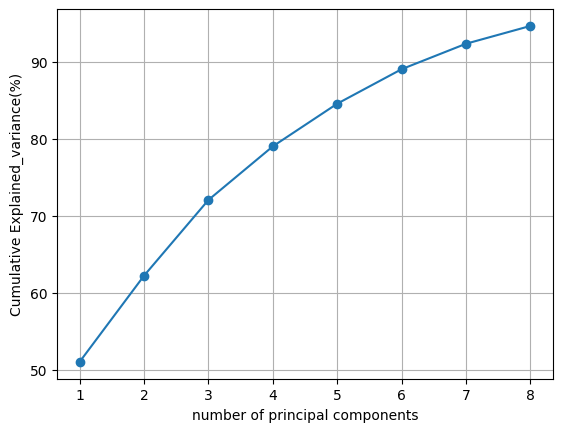

RMESE : 4.963405499893646
R²:  0.6640648675861113


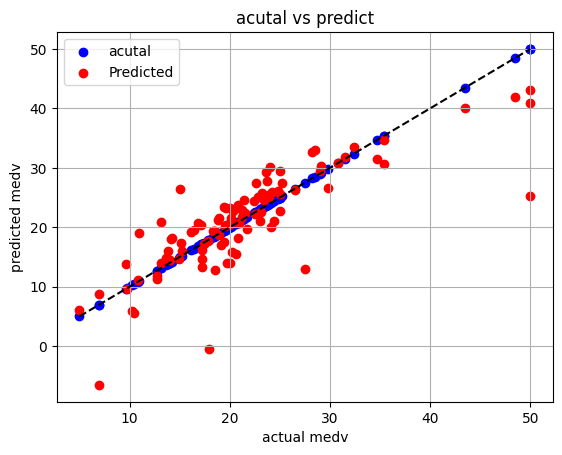

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


train_path = "/content/drive/MyDrive/데이터 분석셋/Boston-house-price-data.csv"

df = pd.read_csv(train_path)
df.info()
df.head()
#crim = 1인당 범죄율, zn = 대형 주택용지 비율, indus = 비소매 상업지역 비율, chas = 찰스강 인접여부(범주형), nox = 대기오염 정도, rm = 평균 방 개수, age = 노후화된 주택 비율, dis = 고용 중심지까지의 거리, rad = 고속도로 접근성 지수,
#tax = 재산세율, ptratio = 학생 교사 비율, b = 흑인 인구 비율, lstat = 저소득층 비율, medv = 주택의 중앙값



df["CRIM"].corr(df["MEDV"])

corr1 = df.corr()[["MEDV"]]

#sns.heatmap(corr1,annot=True,cmap="coolwarm")  #찰스강의 인접여부는 유의미한 상관관계를 보여주지 않음
plt.show()

df["MEDV"]


df2 = df.drop(["CHAS"],axis = 1)
df2.head()


x = df2.drop("MEDV",axis = 1)
y = df2["MEDV"]

scaler = StandardScaler()

x_scaled = scaler.fit_transform(x)
x_scaled

x.shape

pca = PCA(n_components=8)

x_pca = pca.fit_transform(x_scaled)

print(pca.explained_variance_ratio_)



df_pca = pd.DataFrame(x_pca,columns=[f"PC{i}" for i in range(1,9)])
df_pca.head()


y = df2["MEDV"]
df_pca["MEDV"] = y
df_pca.head()
df_pca.info()
cum_ratio = np.cumsum(pca.explained_variance_ratio_) #누적합을 구하는 코드

plt.plot(range(1,len(cum_ratio)+1),cum_ratio * 100, marker = "o")#ratio의 길이에 플러스 1만큼 해서 맞추
plt.xlabel("number of principal components")
plt.ylabel("Cumulative Explained_variance(%)")

plt.xticks(range(1,len(cum_ratio)+1))
plt.grid()
plt.show()

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error,r2_score
x = df2.drop("MEDV",axis = 1)
y = df2["MEDV"]

x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state = 42)

model = LinearRegression()

model.fit(x_train,y_train)

y_pred = model.predict(x_test)

df_val = pd.DataFrame({"Real_value":y_test,"Predict":y_pred})
df_val

print("RMESE :",mean_squared_error(y_test,y_pred)**0.5)#실제값과 예측값의 차이
print("R²: ",r2_score(y_test,y_pred))#모델의 결정계수 1에 가까울수록


plt.scatter(y_test,y_test, label = "acutal",color = "blue")
plt.scatter(y_test,y_pred,label = "Predicted",color = "red")

plt.plot([y_test.min(),y_test.max()],[y_test.min(),y_test.max()],linestyle="--",color = "black")
plt.xlabel("actual medv")
plt.ylabel("predicted medv")
plt.title("acutal vs predict")
plt.legend()
plt.grid()
plt.show()







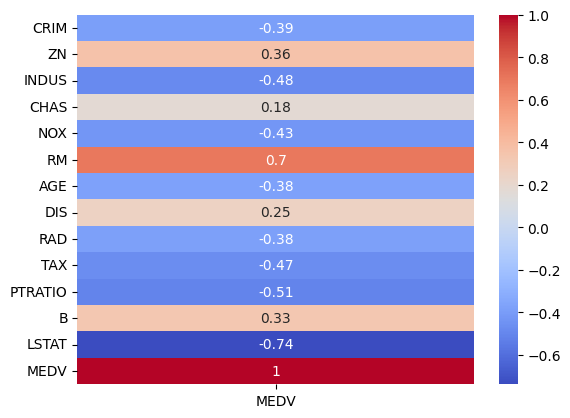

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000104 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1028
[LightGBM] [Info] Number of data points in the train set: 404, number of used features: 12
[LightGBM] [Info] Start training from score 22.796535
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, 

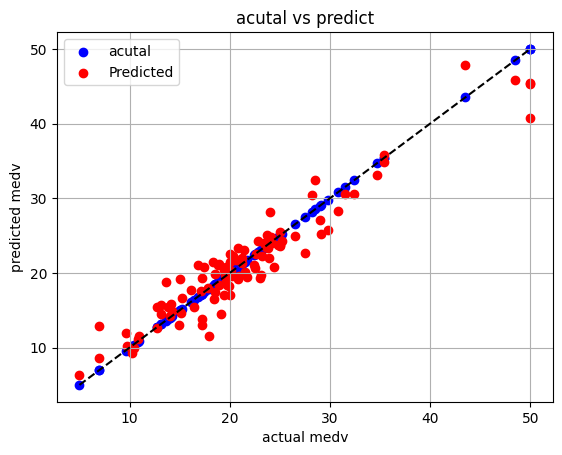

,Model,RMSE,R2
0,Linear Regression,4.963405,0.664065
1,Ridge,4.992419,0.660126
2,Lasso,4.940596,0.667145
3,Randomforest,3.069832,0.871494
4,GradientBoostingRegressor,2.509557,0.914120
5,XGBRegressor,2.852014,0.889083
6,LGBMRegressor,2.859742,0.888481


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

data_path = "/content/drive/MyDrive/데이터 분석셋/Boston-house-price-data.csv"

df = pd.read_csv(data_path)

df.describe()
corr1 = df.corr()[["MEDV"]]

sns.heatmap(corr1,annot=True,cmap="coolwarm")
plt.show()


df1 =df.drop("CHAS",axis = 1)
df1.head()
scaler = StandardScaler()

models = {"Linear Regression":LinearRegression(),"Ridge":Ridge(),"Lasso":Lasso(),"Randomforest":RandomForestRegressor(),"GradientBoostingRegressor":GradientBoostingRegressor(),"XGBRegressor":XGBRegressor(),"LGBMRegressor":LGBMRegressor()}

x = df1.drop("MEDV",axis = 1)
y = df1["MEDV"]
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size = 0.2,random_state = 42)
x = scaler.fit_transform(x)



result = []
for name,model in models.items() :
  model.fit(x_train,y_train)
  y_pred = model.predict(x_test)
  RMSE = mean_squared_error(y_test,y_pred)**0.5
  r2 = r2_score(y_test,y_pred)

  result.append({"Model":name,"RMSE":RMSE,"R2":r2})

results_df = pd.DataFrame(result)



gradientboostingregressor = GradientBoostingRegressor()
gradientboostingregressor.fit(x_train,y_train)
y_pred2 = gradientboostingregressor.predict(x_test)

plt.scatter(y_test,y_test, label = "acutal", color = "blue")
plt.scatter(y_test,y_pred2, label = "Predicted", color= "red")
plt.plot([y_test.min(),y_test.max()],[y_test.min(),y_test.max()],linestyle="--",color = "black")
plt.xlabel("actual medv")
plt.ylabel("predicted medv")
plt.title("acutal vs predict")
plt.legend()
plt.grid()
plt.show()
results_df



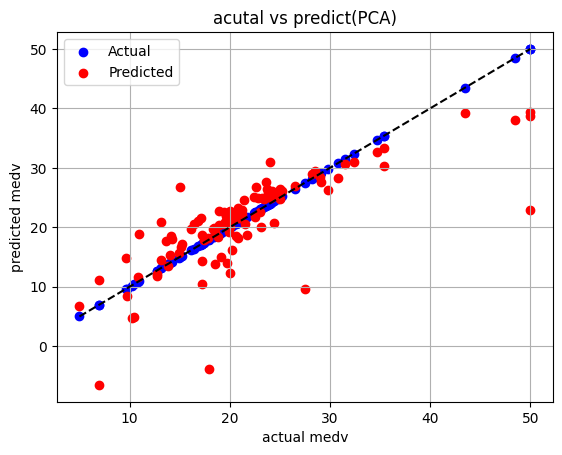

RMSE:  5.505967259994019
R²:  0.5866069611893654


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score


data_path = "/content/drive/MyDrive/데이터 분석셋/Boston-house-price-data.csv"

df = pd.read_csv(data_path)

df = df.drop("CHAS",axis = 1)

x = df.drop("MEDV",axis = 1)
y = df["MEDV"]


x_train,x_test,y_train,y_test = train_test_split(x,y,test_size = 0.2,random_state = 42)

model = Pipeline([("scaler",StandardScaler()),("pca",PCA(n_components=8)),("regression",LinearRegression())])#이거 기억해두자

model.fit(x_train,y_train)

y_pred = model.predict(x_test)

result = pd.DataFrame({"Real_value":y_test,"Predict":y_pred})

result

plt.scatter(y_test,y_test,label = "Actual",color = "blue")
plt.scatter(y_test,y_pred,label = "Predicted",color = "red")

plt.plot([y_test.min(),y_test.max()],[y_test.min(),y_test.max()],linestyle="--",color = "black")
plt.xlabel("actual medv")
plt.ylabel("predicted medv")
plt.title("acutal vs predict(PCA)")
plt.legend()
plt.grid()
plt.show()


print("RMSE: ",mean_squared_error(y_test,y_pred)**0.5)
print("R²: ",r2_score(y_test,y_pred))